# Design and Development of a Telecom Customer Churn Prediction System

**Course:** Machine Learning Model Engineering  
**Dataset:** IBM Telco Customer Churn

This project develops a customer churn classification system and evaluates its suitability for deployment. The workflow covers data preparation, exploratory analysis, model development, evaluation, model persistence, API-based inference, performance measurement and data-drift monitoring.

**Dataset scope:** The dataset contains a cross-sectional customer snapshot and does not include dated customer histories. The modelling task is therefore classification of the recorded churn label using the available customer attributes. A temporal prediction claim is not made.

## 1. Environment setup

In [1]:
%pip install -q \
    "numpy<2.5" \
    "pandas==2.2.3" \
    scikit-learn \
    matplotlib \
    seaborn \
    joblib \
    fastapi \
    uvicorn \
    httpx

In [2]:
import numpy
import pandas
import sklearn

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1


In [3]:
import os, sys, json, time, warnings, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
PROJECT_DIR = Path("/content/telecom-churn-production-ml")
DATA_DIR = PROJECT_DIR / "data" / "raw"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
REPORT_DIR = PROJECT_DIR / "reports"
for p in [DATA_DIR, ARTIFACT_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("scikit-learn:", sklearn.__version__)
print("Project directory:", PROJECT_DIR)

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
scikit-learn: 1.6.1
Project directory: /content/telecom-churn-production-ml


## 2. Download the IBM dataset

In [4]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
RAW_PATH = DATA_DIR / "Telco-Customer-Churn.csv"

if not RAW_PATH.exists():
    df_raw = pd.read_csv(DATA_URL)
    df_raw.to_csv(RAW_PATH, index=False)
else:
    df_raw = pd.read_csv(RAW_PATH)

file_hash = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
print("Downloaded/read:", RAW_PATH)
print("SHA-256:", file_hash)
print("Shape:", df_raw.shape)
display(df_raw.head())

Downloaded/read: /content/telecom-churn-production-ml/data/raw/Telco-Customer-Churn.csv
SHA-256: a0ea74c48c1063be89a73ce3fb868593604c0129f2bf581934f04983d728b3b5
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Dataset understanding and quality checks

In [5]:
print("Rows, columns:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nData types and non-null counts:")
df_raw.info()
print("\nMissing values:")
display(df_raw.isna().sum().to_frame("missing_count"))
print("\nExact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate customer IDs:", df_raw["customerID"].duplicated().sum())
print("\nTarget counts:")
display(df_raw["Churn"].value_counts(dropna=False).to_frame("count"))
display((df_raw["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

Rows, columns: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   70

,missing_count
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Exact duplicate rows: 0
Duplicate customer IDs: 0

Target counts:


,count
Churn,
No,5174
Yes,1869


,percent
Churn,
No,73.46
Yes,26.54


In [6]:
# TotalCharges is stored as text in the source; inspect whitespace-only entries before conversion.
blank_total_charges = df_raw["TotalCharges"].astype(str).str.strip().eq("").sum()
print("Blank/whitespace TotalCharges:", blank_total_charges)

df_raw["TotalCharges"] = pd.to_numeric(
    df_raw["TotalCharges"].astype(str).str.strip(), errors="coerce"
)
print("Missing TotalCharges after numeric conversion:", df_raw["TotalCharges"].isna().sum())

quality_summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "unique": df_raw.nunique(dropna=False)
})
display(quality_summary)

Blank/whitespace TotalCharges: 11
Missing TotalCharges after numeric conversion: 11


,dtype,missing,unique
customerID,object,0,7043
gender,object,0,2
SeniorCitizen,int64,0,2
Partner,object,0,2
Dependents,object,0,2
tenure,int64,0,73
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3
OnlineSecurity,object,0,3


## 4. Exploratory data analysis

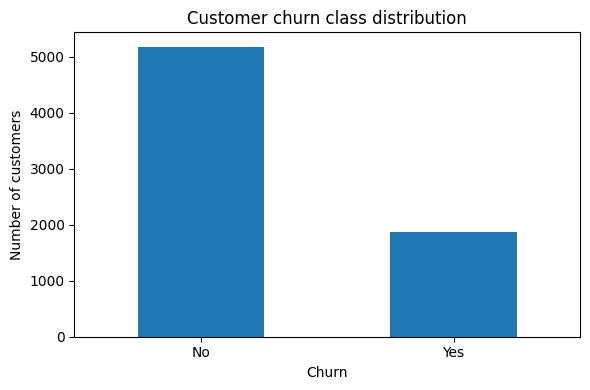

Churn percentage:


,percentage
Churn,
No,73.46
Yes,26.54


In [7]:
df_eda = df_raw.copy()
df_eda["Churn"].value_counts().plot(kind="bar", figsize=(6,4))
plt.title("Customer churn class distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Churn percentage:")
display((df_eda["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


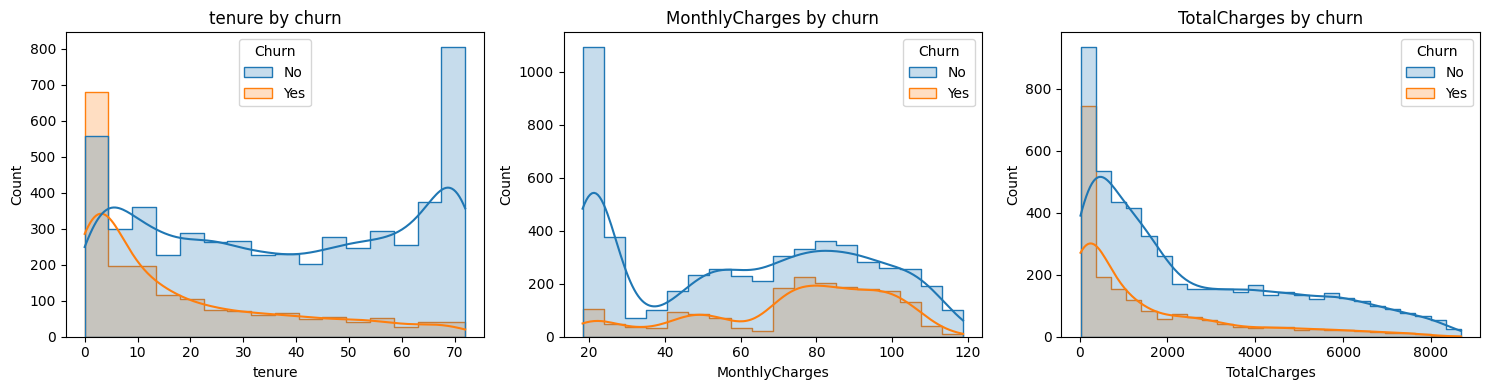

In [8]:
numeric_for_eda = ["tenure", "MonthlyCharges", "TotalCharges"]
display(df_eda[numeric_for_eda].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_for_eda):
    sns.histplot(data=df_eda, x=col, hue="Churn", kde=True, ax=ax, element="step")
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

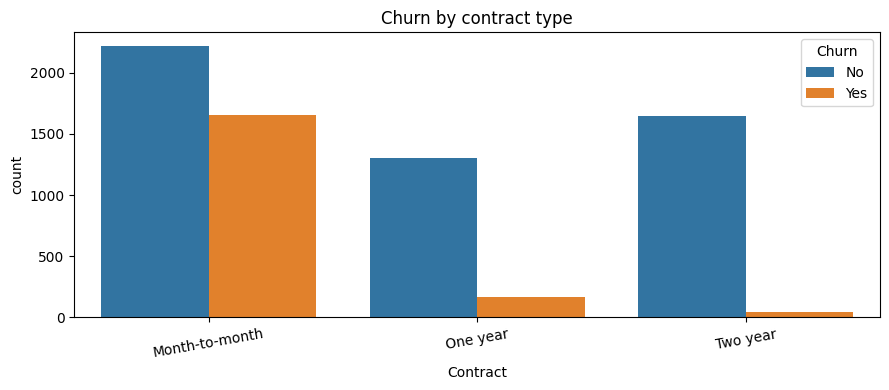

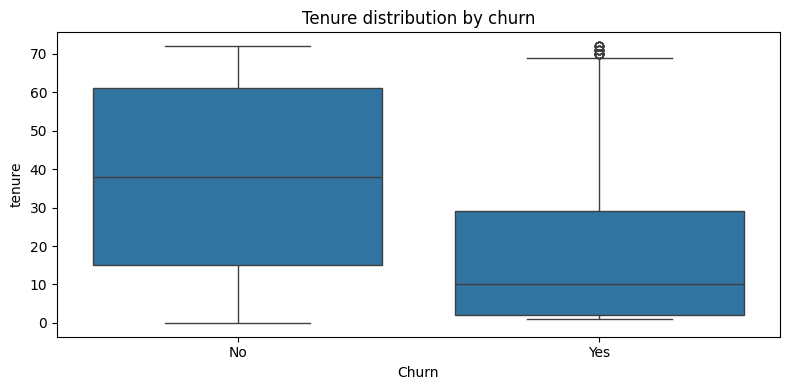

In [9]:
plt.figure(figsize=(9, 4))
sns.countplot(data=df_eda, x="Contract", hue="Churn")
plt.title("Churn by contract type")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(data=df_eda, x="Churn", y="tenure")
plt.title("Tenure distribution by churn")
plt.tight_layout()
plt.show()

### Exploratory analysis

The plots and descriptive statistics provide an overview of class distribution, tenure, monthly charges and contract categories. These patterns are descriptive and should not be interpreted as evidence of causation.

## 5. Problem formulation and feature definition

**Business objective:** provide a churn-risk score that can help a telecom retention team prioritise customer outreach.

**Target:** `Churn` (`Yes` = 1, `No` = 0).

**Excluded identifier:** `customerID` is retained for record traceability in scoring output but excluded from model features.

**Evaluation design:** stratified 70% training, 15% validation and 15% test partitions. Stratification preserves class proportions because this dataset is cross-sectional and has no usable event-time field. The test set is held back until final evaluation.

**Leakage control:** split raw records before fitting transformations. Imputers, scaling and category encoders are fitted inside the model pipeline using training records only. No synthetic oversampling is applied. Class weighting is used as a training-time option.

In [10]:
# Work on a copy; do not modify the preserved raw CSV.
df = df_raw.copy()
df = df.drop_duplicates().reset_index(drop=True)

# Remove rows with missing target, if any; keep missing feature values for pipeline imputation.
df = df[df["Churn"].isin(["Yes", "No"])].copy()
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

# The identifier is not a predictor.
customer_ids = df["customerID"].astype(str).reset_index(drop=True)
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].reset_index(drop=True)

# Identify column types from the raw feature frame.
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Rows used:", len(df))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target counts:")
display(y.value_counts().rename(index={0:"No churn", 1:"Churn"}).to_frame("count"))

Rows used: 7043
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Target counts:


,count
Churn,
No churn,5174
Churn,1869


In [11]:
# 70 / 15 / 15 stratified split: first isolate test, then split remaining data.
X_train, X_temp, y_train, y_temp, id_train, id_temp = train_test_split(
    X, y, customer_ids, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test, id_valid, id_test = train_test_split(
    X_temp, y_temp, id_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

split_summary = pd.DataFrame({
    "partition": ["train", "validation", "test"],
    "rows": [len(X_train), len(X_valid), len(X_test)],
    "churn_rate": [y_train.mean(), y_valid.mean(), y_test.mean()]
})
display(split_summary)
assert set(id_train).isdisjoint(set(id_valid))
assert set(id_train).isdisjoint(set(id_test))
assert set(id_valid).isdisjoint(set(id_test))

,partition,rows,churn_rate
0,train,4930,0.265314
1,validation,1056,0.265152
2,test,1057,0.265847


## 6. Leakage-free preprocessing and model pipelines

In [12]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

def make_pipeline(model):
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

models = {
    "Dummy baseline": make_pipeline(DummyClassifier(strategy="prior")),
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1
        )
    )
}
print("Pipelines created. Preprocessing will be fitted only when each pipeline is fit on X_train.")

Pipelines created. Preprocessing will be fitted only when each pipeline is fit on X_train.


## 7. Train models and compare validation performance

In [13]:
def metric_row(name, model, X_eval, y_eval, threshold=0.5):
    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    return {
        "model": name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_eval, predictions),
        "precision": precision_score(y_eval, predictions, zero_division=0),
        "recall": recall_score(y_eval, predictions, zero_division=0),
        "f1": f1_score(y_eval, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, probabilities),
        "average_precision_PR_AUC": average_precision_score(y_eval, probabilities)
    }

validation_rows = []
for name, pipe in models.items():
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    row = metric_row(name, pipe, X_valid, y_valid)
    row["training_seconds"] = fit_seconds
    validation_rows.append(row)

validation_results = pd.DataFrame(validation_rows).sort_values(
    "average_precision_PR_AUC", ascending=False
)
display(validation_results)


,model,threshold,accuracy,precision,recall,f1,roc_auc,average_precision_PR_AUC,training_seconds
1,Logistic Regression,0.5,0.739583,0.505543,0.814286,0.623803,0.844677,0.630759,0.554428
2,Random Forest,0.5,0.777462,0.570093,0.653571,0.608985,0.830695,0.608539,6.504315
0,Dummy baseline,0.5,0.734848,0.000000,0.000000,0.000000,0.500000,0.265152,0.166721


## 8. Select a model and tune the operating threshold on validation data

Selected model: Logistic Regression
Validation-selected threshold: 0.5397
Validation F1 at selected threshold: 0.6329


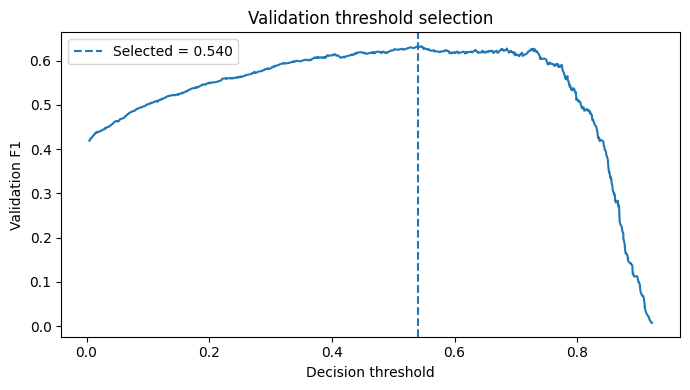

In [14]:
# Select the best validation PR-AUC model. The test set remains untouched.
selected_name = validation_results.iloc[0]["model"]
selected_pipeline = models[selected_name]
valid_prob = selected_pipeline.predict_proba(X_valid)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_valid, valid_prob)
# Choose the threshold that maximises validation F1. This is a transparent starting policy;
# a real retention team should tune it using outreach capacity and business costs.
f1_values = (2 * precision[:-1] * recall[:-1]) / (
    precision[:-1] + recall[:-1] + 1e-12
)
best_idx = int(np.nanargmax(f1_values))
selected_threshold = float(thresholds[best_idx])

print("Selected model:", selected_name)
print("Validation-selected threshold:", round(selected_threshold, 4))
print("Validation F1 at selected threshold:", round(float(f1_values[best_idx]), 4))

plt.figure(figsize=(7,4))
plt.plot(thresholds, f1_values)
plt.axvline(selected_threshold, linestyle="--", label=f"Selected = {selected_threshold:.3f}")
plt.xlabel("Decision threshold")
plt.ylabel("Validation F1")
plt.title("Validation threshold selection")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Final held-out test evaluation

,test_value
selected_model,Logistic Regression
threshold,0.539746
accuracy,0.762535
precision,0.538462
recall,0.747331
f1,0.625931
roc_auc,0.844627
average_precision_PR_AUC,0.658615


              precision    recall  f1-score   support

    No churn       0.89      0.77      0.83       776
       Churn       0.54      0.75      0.63       281

    accuracy                           0.76      1057
   macro avg       0.72      0.76      0.73      1057
weighted avg       0.80      0.76      0.77      1057



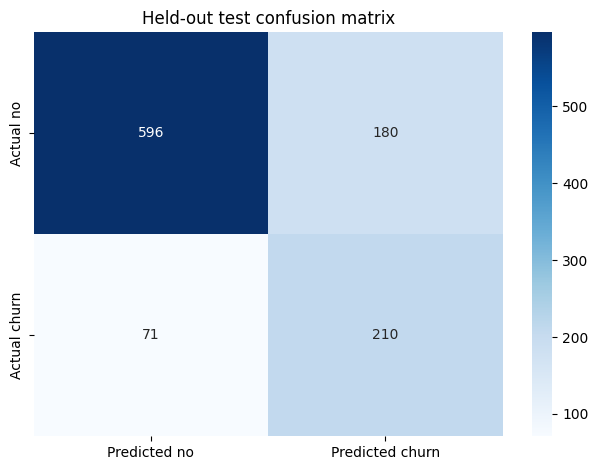

In [15]:
test_prob = selected_pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)

test_metrics = {
    "selected_model": selected_name,
    "threshold": selected_threshold,
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_prob),
    "average_precision_PR_AUC": average_precision_score(y_test, test_prob)
}
display(pd.DataFrame([test_metrics]).T.rename(columns={0:"test_value"}))
print(classification_report(y_test, test_pred, target_names=["No churn", "Churn"], zero_division=0))

cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted no", "Predicted churn"],
            yticklabels=["Actual no", "Actual churn"])
plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

In [16]:
# Save reproducibility metadata and model artefact.
MODEL_PATH = ARTIFACT_DIR / "churn_pipeline.joblib"
METADATA_PATH = ARTIFACT_DIR / "model_metadata.json"

joblib.dump(selected_pipeline, MODEL_PATH)
metadata = {
    "project": "Telecom Customer Churn Prediction",
    "model_name": selected_name,
    "decision_threshold": selected_threshold,
    "target_mapping": {"No": 0, "Yes": 1},
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "feature_columns": X.columns.tolist(),
    "training_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "random_state": RANDOM_STATE,
    "library_versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__
    },
    "dataset_sha256": file_hash,
    "test_metrics": {k: float(v) if isinstance(v, (np.floating, np.integer)) else v
                     for k, v in test_metrics.items()}
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2))
print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)

Saved model: /content/telecom-churn-production-ml/artifacts/churn_pipeline.joblib
Saved metadata: /content/telecom-churn-production-ml/artifacts/model_metadata.json


## 10. Inference helper and batch scoring

In [17]:
# Reload from disk to verify that the serialized artefact works independently of training variables.
loaded_model = joblib.load(MODEL_PATH)
loaded_metadata = json.loads(METADATA_PATH.read_text())
MODEL_THRESHOLD = float(loaded_metadata["decision_threshold"])
FEATURE_COLUMNS = loaded_metadata["feature_columns"]

def score_records(records: pd.DataFrame) -> pd.DataFrame:
    missing_cols = [c for c in FEATURE_COLUMNS if c not in records.columns]
    extra_cols = [c for c in records.columns if c not in FEATURE_COLUMNS]
    if missing_cols:
        raise ValueError(f"Missing required feature columns: {missing_cols}")
    if extra_cols:
        # Extra fields are ignored explicitly; only training-time features are passed to the model.
        records = records.drop(columns=extra_cols)
    ordered = records[FEATURE_COLUMNS].copy()
    probabilities = loaded_model.predict_proba(ordered)[:, 1]
    predictions = (probabilities >= MODEL_THRESHOLD).astype(int)
    return pd.DataFrame({
        "churn_probability": probabilities,
        "predicted_churn": predictions,
        "risk_band": pd.cut(probabilities, bins=[-0.001, 0.30, 0.60, 1.0],
                            labels=["Low", "Medium", "High"]).astype(str)
    })

sample_batch = X_test.head(10).copy()
display(score_records(sample_batch).head())

,churn_probability,predicted_churn,risk_band
0,0.679332,1,High
1,0.225599,0,Low
2,0.078108,0,Low
3,0.350526,0,Medium
4,0.020583,0,Low


## 11. Create a FastAPI REST inference service

In [18]:
SERVING_DIR = PROJECT_DIR / "serving"
SERVING_DIR.mkdir(exist_ok=True)

app_source = r"""
import json
from pathlib import Path

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict

BASE_DIR = Path(__file__).resolve().parents[1]
MODEL_PATH = BASE_DIR / "artifacts" / "churn_pipeline.joblib"
META_PATH = BASE_DIR / "artifacts" / "model_metadata.json"

app = FastAPI(title="Telecom Churn Prediction API", version="1.1.0")
model = None
metadata = None

class CustomerRecord(BaseModel):
    model_config = ConfigDict(extra="forbid")

    gender: str | None = None
    SeniorCitizen: int | None = None
    Partner: str | None = None
    Dependents: str | None = None
    tenure: float | None = None
    PhoneService: str | None = None
    MultipleLines: str | None = None
    InternetService: str | None = None
    OnlineSecurity: str | None = None
    OnlineBackup: str | None = None
    DeviceProtection: str | None = None
    TechSupport: str | None = None
    StreamingTV: str | None = None
    StreamingMovies: str | None = None
    Contract: str | None = None
    PaperlessBilling: str | None = None
    PaymentMethod: str | None = None
    MonthlyCharges: float | None = None
    TotalCharges: float | None = None

@app.on_event("startup")
def load_artifacts():
    global model, metadata
    if not MODEL_PATH.exists() or not META_PATH.exists():
        model = None
        metadata = None
        return
    model = joblib.load(MODEL_PATH)
    metadata = json.loads(META_PATH.read_text())

@app.get("/health")
def health():
    ready = model is not None and metadata is not None
    return {"status": "ok" if ready else "unavailable", "model_loaded": ready}

@app.post("/predict")
def predict(record: CustomerRecord):
    if model is None or metadata is None:
        raise HTTPException(status_code=503, detail="Model artefact is unavailable")
    row = pd.DataFrame([record.model_dump()])
    row = row[metadata["feature_columns"]]
    probability = float(model.predict_proba(row)[0, 1])
    threshold = float(metadata["decision_threshold"])
    prediction = int(probability >= threshold)
    band = "High" if probability >= 0.60 else ("Medium" if probability >= 0.30 else "Low")
    return {
        "churn_probability": probability,
        "predicted_churn": prediction,
        "predicted_label": "Yes" if prediction else "No",
        "risk_band": band,
        "threshold": threshold
    }

@app.post("/predict/batch")
def predict_batch(records: list[CustomerRecord]):
    if model is None or metadata is None:
        raise HTTPException(status_code=503, detail="Model artefact is unavailable")
    if not records:
        raise HTTPException(status_code=422, detail="At least one record is required")
    frame = pd.DataFrame([record.model_dump() for record in records])
    frame = frame[metadata["feature_columns"]]
    probabilities = model.predict_proba(frame)[:, 1]
    threshold = float(metadata["decision_threshold"])
    return {"predictions": [
        {
            "churn_probability": float(probability),
            "predicted_churn": int(probability >= threshold)
        }
        for probability in probabilities
    ]}
"""
(SERVING_DIR / "app.py").write_text(app_source)
print("FastAPI application saved to:", SERVING_DIR / "app.py")


FastAPI application saved to: /content/telecom-churn-production-ml/serving/app.py


### API validation and robustness tests

In [19]:
import importlib.util
from fastapi.testclient import TestClient

spec = importlib.util.spec_from_file_location("churn_api_app", SERVING_DIR / "app.py")
api_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(api_module)

with TestClient(api_module.app) as client:
    health_response = client.get("/health")
    assert health_response.status_code == 200
    assert health_response.json()["model_loaded"] is True

    sample_payload = X_test.iloc[0].to_dict()
    sample_payload = {
        key: (value.item() if hasattr(value, "item") else value)
        for key, value in sample_payload.items()
    }

    prediction_response = client.post("/predict", json=sample_payload)
    assert prediction_response.status_code == 200

    # Missing values are accepted by the request schema and imputed by the fitted pipeline.
    missing_payload = sample_payload.copy()
    missing_payload["TotalCharges"] = None
    missing_payload["MonthlyCharges"] = None
    missing_response = client.post("/predict", json=missing_payload)
    assert missing_response.status_code == 200

    # An unseen category is accepted and handled by OneHotEncoder(handle_unknown="ignore").
    unknown_payload = sample_payload.copy()
    unknown_payload["Contract"] = "__UNSEEN_CATEGORY__"
    unknown_response = client.post("/predict", json=unknown_payload)
    assert unknown_response.status_code == 200

    # Unexpected fields are rejected by the Pydantic schema.
    malformed_payload = sample_payload.copy()
    malformed_payload["unexpected_field"] = "not_allowed"
    malformed_response = client.post("/predict", json=malformed_payload)
    assert malformed_response.status_code == 422

    batch_payload = [sample_payload, missing_payload]
    batch_response = client.post("/predict/batch", json=batch_payload)
    assert batch_response.status_code == 200
    assert len(batch_response.json()["predictions"]) == 2

print("Health endpoint:", health_response.status_code, health_response.json())
print("Single prediction:", prediction_response.status_code, prediction_response.json())
print("Missing-value request:", missing_response.status_code)
print("Unknown-category request:", unknown_response.status_code)
print("Malformed request:", malformed_response.status_code, "(expected 422)")
print("Batch prediction:", batch_response.status_code, "(2 records)")


Health endpoint: 200 {'status': 'ok', 'model_loaded': True}
Single prediction: 200 {'churn_probability': 0.6793324798164322, 'predicted_churn': 1, 'predicted_label': 'Yes', 'risk_band': 'High', 'threshold': 0.5397463364144385}
Missing-value request: 200
Unknown-category request: 200
Malformed request: 422 (expected 422)
Batch prediction: 200 (2 records)


## 12. REST API performance profiling

### REST API performance measurement

The API benchmark measures `/predict` and `/predict/batch` using FastAPI's in-process `TestClient`. The measurements include request validation, preprocessing, model inference and response serialization. They exclude external network transport and should not be interpreted as public deployment latency. Ten warm-up calls are excluded from the reported samples. The benchmark reports p50, p95 and p99 request latency and sequential throughput.

In [20]:
# The TestClient measures in-process HTTP request handling, including validation,
# preprocessing, prediction and response serialization. It does not include network latency.
import importlib.util
from fastapi.testclient import TestClient

spec = importlib.util.spec_from_file_location("churn_api_benchmark_app", SERVING_DIR / "app.py")
benchmark_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(benchmark_module)

benchmark_payload = X_test.iloc[0].to_dict()
benchmark_payload = {
    key: (value.item() if hasattr(value, "item") else value)
    for key, value in benchmark_payload.items()
}

single_request_latencies_ms = []
batch_request_latencies_ms = []
request_count = 200
batch_size = min(32, len(X_test))
batch_payload = []

for _, row in X_test.head(batch_size).iterrows():
    batch_payload.append({
        key: (value.item() if hasattr(value, "item") else value)
        for key, value in row.to_dict().items()
    })

with TestClient(benchmark_module.app) as benchmark_client:
    # Warm-up requests are excluded from the reported measurements.
    for _ in range(10):
        warmup = benchmark_client.post("/predict", json=benchmark_payload)
        assert warmup.status_code == 200

    for _ in range(request_count):
        start_time = time.perf_counter()
        response = benchmark_client.post("/predict", json=benchmark_payload)
        elapsed_ms = (time.perf_counter() - start_time) * 1000
        assert response.status_code == 200
        single_request_latencies_ms.append(elapsed_ms)

    for _ in range(10):
        warmup = benchmark_client.post("/predict/batch", json=batch_payload)
        assert warmup.status_code == 200

    batch_iterations = 50
    for _ in range(batch_iterations):
        start_time = time.perf_counter()
        response = benchmark_client.post("/predict/batch", json=batch_payload)
        elapsed_ms = (time.perf_counter() - start_time) * 1000
        assert response.status_code == 200
        batch_request_latencies_ms.append(elapsed_ms)

single_latencies = np.asarray(single_request_latencies_ms)
batch_latencies = np.asarray(batch_request_latencies_ms)

api_profiling = {
    "benchmark_environment": "Google Colab; FastAPI TestClient in-process",
    "single_endpoint_requests": int(len(single_latencies)),
    "single_request_latency_p50_ms": float(np.percentile(single_latencies, 50)),
    "single_request_latency_p95_ms": float(np.percentile(single_latencies, 95)),
    "single_request_latency_p99_ms": float(np.percentile(single_latencies, 99)),
    "single_request_latency_mean_ms": float(single_latencies.mean()),
    "single_request_throughput_requests_per_second": float(1000 / single_latencies.mean()),
    "batch_size_records": int(batch_size),
    "batch_endpoint_requests": int(len(batch_latencies)),
    "batch_request_latency_p50_ms": float(np.percentile(batch_latencies, 50)),
    "batch_request_latency_p95_ms": float(np.percentile(batch_latencies, 95)),
    "batch_request_latency_p99_ms": float(np.percentile(batch_latencies, 99)),
    "batch_records_per_second": float(
        (batch_size * len(batch_latencies)) / (batch_latencies.sum() / 1000)
    )
}

display(pd.DataFrame([api_profiling]).T.rename(columns={0: "measured_value"}))
(REPORT_DIR / "api_profiling.json").write_text(json.dumps(api_profiling, indent=2))
pd.DataFrame({
    "single_request_latency_ms": pd.Series(single_latencies),
    "batch_request_latency_ms": pd.Series(batch_latencies)
}).to_csv(REPORT_DIR / "api_latency_samples.csv", index=False)

print("API profiling saved to:", REPORT_DIR / "api_profiling.json")


,measured_value
benchmark_environment,Google Colab; FastAPI TestClient in-process
single_endpoint_requests,200
single_request_latency_p50_ms,24.927715
single_request_latency_p95_ms,69.211988
single_request_latency_p99_ms,84.670676
single_request_latency_mean_ms,31.705167
single_request_throughput_requests_per_second,31.540601
batch_size_records,32
batch_endpoint_requests,50
batch_request_latency_p50_ms,25.087672


API profiling saved to: /content/telecom-churn-production-ml/reports/api_profiling.json


## 13. Pipeline-level robustness checks

In [21]:
# Missing numeric/categorical feature values should be handled by fitted imputers.
missing_case = X_test.head(1).copy()
missing_case.loc[missing_case.index[0], numeric_features[0]] = np.nan
if categorical_features:
    missing_case.loc[missing_case.index[0], categorical_features[0]] = np.nan
print("Prediction with missing feature values:")
display(score_records(missing_case))

# Unknown category test: OneHotEncoder(handle_unknown='ignore') should handle unseen labels.
unknown_case = X_test.head(1).copy()
if categorical_features:
    unknown_case.loc[unknown_case.index[0], categorical_features[0]] = "__UNSEEN_CATEGORY__"
print("Prediction with an unseen category:")
display(score_records(unknown_case))

# Missing required columns should fail clearly rather than produce a silent prediction.
try:
    score_records(X_test.head(1).drop(columns=[FEATURE_COLUMNS[0]]))
except ValueError as exc:
    print("Expected validation failure:", exc)

Prediction with missing feature values:


,churn_probability,predicted_churn,risk_band
0,0.647087,1,High


Prediction with an unseen category:


,churn_probability,predicted_churn,risk_band
0,0.693506,1,High


Expected validation failure: Missing required feature columns: ['gender']


## 14. Data drift monitoring demonstration (PSI and KS)

The drift demonstration compares the training partition with the held-out test partition as a proxy reference batch. This is an offline demonstration using data available at development time, not evidence of live production monitoring. In deployment, each incoming scoring batch should be compared with a fixed training/reference population.

Population Stability Index (PSI) is calculated for numeric and categorical features. The two-sample Kolmogorov–Smirnov (KS) test is applied to numeric features. PSI alert bands of 0.10 and 0.20 are operational heuristics and should be calibrated to the application and sample size.

In [22]:
from scipy.stats import ks_2samp

def calculate_psi(expected, actual, bins=10):
    expected = pd.Series(expected).dropna()
    actual = pd.Series(actual).dropna()
    if len(expected) == 0 or len(actual) == 0:
        return np.nan
    if pd.api.types.is_numeric_dtype(expected):
        edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
        if len(edges) < 3:
            edges = np.linspace(expected.min() - 1e-9, expected.max() + 1e-9, bins + 1)
        exp_counts = np.histogram(expected, bins=edges)[0]
        act_counts = np.histogram(actual.clip(edges[0], edges[-1]), bins=edges)[0]
    else:
        cats = sorted(set(expected.astype(str)) | set(actual.astype(str)))
        exp_counts = expected.astype(str).value_counts().reindex(cats, fill_value=0).values
        act_counts = actual.astype(str).value_counts().reindex(cats, fill_value=0).values
    exp_pct = exp_counts / max(exp_counts.sum(), 1)
    act_pct = act_counts / max(act_counts.sum(), 1)
    eps = 1e-6
    exp_pct = np.clip(exp_pct, eps, None)
    act_pct = np.clip(act_pct, eps, None)
    return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct)))

drift_rows = []
for col in X_train.columns:
    psi = calculate_psi(X_train[col], X_test[col])
    row = {"feature": col, "psi": psi, "psi_status": (
        "Review" if psi >= 0.20 else ("Watch" if psi >= 0.10 else "No alert")
    )}
    if pd.api.types.is_numeric_dtype(X_train[col]):
        ks_stat, ks_p = ks_2samp(X_train[col].dropna(), X_test[col].dropna())
        row.update({"ks_statistic": float(ks_stat), "ks_p_value": float(ks_p)})
    else:
        row.update({"ks_statistic": np.nan, "ks_p_value": np.nan})
    drift_rows.append(row)

drift_report = pd.DataFrame(drift_rows).sort_values("psi", ascending=False)
display(drift_report)
drift_report.to_csv(REPORT_DIR / "drift_monitoring_demo.csv", index=False)

,feature,psi,psi_status,ks_statistic,ks_p_value
18,TotalCharges,0.017135,No alert,0.025011,0.637922
17,MonthlyCharges,0.016022,No alert,0.040886,0.105530
4,tenure,0.005827,No alert,0.022936,0.739160
13,StreamingMovies,0.005297,No alert,NaN,NaN
12,StreamingTV,0.005036,No alert,NaN,NaN
11,TechSupport,0.004301,No alert,NaN,NaN
6,MultipleLines,0.002617,No alert,NaN,NaN
7,InternetService,0.002423,No alert,NaN,NaN
0,gender,0.001537,No alert,NaN,NaN
15,PaperlessBilling,0.001337,No alert,NaN,NaN


## 15. System considerations, fallback and operational thresholds

### Input validation and failure handling
- FastAPI/Pydantic validates required fields and types; malformed requests receive HTTP 422.
- Unknown categorical values are handled by `OneHotEncoder(handle_unknown='ignore')`.
- Missing feature values are imputed by the fitted pipeline.
- If model files are absent, `/health` reports `unavailable` and prediction endpoints return HTTP 503.
- The API does not invent a prediction when the model is unavailable; the caller should use a manual retention-review queue or retry after service recovery.

### Monitoring and response
- Track p50/p95/p99 REST endpoint latency, throughput, HTTP error rate and missing/invalid input rate. Separate in-process service measurements from external network latency.
- Track PSI and category-frequency drift; investigate PSI >= 0.20 and monitor 0.10–0.20.
- Use KS test as a numeric distribution-change signal; interpret p-values with sample size in mind.
- Once true churn outcomes become available, monitor PR-AUC/recall and calibration on labelled production cohorts. Feature drift alone does not prove model performance has degraded.
- Retrain only after validating drift, label-based performance decline, data quality and business impact. Keep the current model as a rollback artefact.

### Deployment note
This notebook creates the FastAPI source and tests it in-process. For an external deployment, pin dependencies, package the `artifacts/` and `serving/` folders, add container configuration, authentication, HTTPS, logging and a model-version/rollback process.

## 16. Export project outputs

In [23]:
# Save core result tables and a run summary for the report.
validation_results.to_csv(REPORT_DIR / "validation_model_comparison.csv", index=False)
pd.DataFrame([test_metrics]).to_csv(REPORT_DIR / "heldout_test_metrics.csv", index=False)
split_summary.to_csv(REPORT_DIR / "data_split_summary.csv", index=False)

import importlib.metadata as package_metadata
required_packages = ["numpy", "pandas", "scikit-learn", "joblib", "fastapi", "uvicorn", "pydantic", "httpx"]
package_versions = {name: package_metadata.version(name) for name in required_packages}
requirements_text = "\n".join(f"{name}=={version}" for name, version in package_versions.items()) + "\n"
(PROJECT_DIR / "requirements.txt").write_text(requirements_text)

run_summary = {
    "dataset_shape_raw": list(df_raw.shape),
    "dataset_shape_modeling": list(df.shape),
    "blank_total_charges_before_conversion": int(blank_total_charges),
    "duplicate_rows_removed": int(df_raw.duplicated().sum()),
    "split": split_summary.to_dict(orient="records"),
    "validation_results": validation_results.to_dict(orient="records"),
    "test_metrics": test_metrics,
    "api_profiling": api_profiling,
    "package_versions": package_versions,
    "artifact": str(MODEL_PATH),
    "metadata": str(METADATA_PATH)
}
(REPORT_DIR / "run_summary.json").write_text(json.dumps(run_summary, indent=2, default=str))
print("Project output files:")
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT_DIR))

Project output files:
artifacts/churn_pipeline.joblib
artifacts/model_metadata.json
data/raw/Telco-Customer-Churn.csv
reports/api_latency_samples.csv
reports/api_profiling.json
reports/data_split_summary.csv
reports/drift_monitoring_demo.csv
reports/heldout_test_metrics.csv
reports/run_summary.json
reports/validation_model_comparison.csv
requirements.txt
serving/__pycache__/app.cpython-313.pyc
serving/app.py


## 17. Project outputs

- `artifacts/churn_pipeline.joblib` — fitted preprocessing and classification pipeline.
- `artifacts/model_metadata.json` — model configuration, threshold and evaluation metadata.
- `reports/validation_model_comparison.csv` — validation metrics for candidate models.
- `reports/heldout_test_metrics.csv` — final test-set metrics.
- `reports/data_split_summary.csv` — partition sizes and class proportions.
- `reports/drift_monitoring_demo.csv` — feature distribution monitoring results.
- `reports/run_summary.json` — summary of the experiment and measured system performance.